In [1]:
import pandas as pd

import numpy as np

from collections import OrderedDict

import matplotlib.pyplot as plt

import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

import scipy.stats as sci

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV , learning_curve

from sklearn.metrics import mean_squared_error , r2_score

from sklearn.linear_model import LinearRegression , Lasso , Ridge

from sklearn.tree import DecisionTreeRegressor 

from sklearn.neighbors import KNeighborsRegressor

from sklearn.svm import SVR

from sklearn.ensemble import RandomForestRegressor , AdaBoostRegressor,GradientBoostingRegressor

import xgboost 

from xgboost import XGBRegressor


In [2]:
# Cement data - percentage of each material  mixed in the cement is used for various purposes.
# Age - duration of the cement
# "Strength" is the target feature 

In [3]:
# Cement Data

df = pd.read_excel("Capstone Project.xlsx")

In [4]:
df_bkp = pd.read_excel("Capstone Project.xlsx")

In [5]:
df.head()

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength
0,141.3,212.0,0.0,203.5,0.0,971.8,748.5,28,29.89
1,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,14,23.51
2,250.0,0.0,95.7,187.4,5.5,956.9,861.2,28,29.22
3,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.85
4,154.8,183.4,0.0,193.3,9.1,1047.4,696.7,28,18.29


In [6]:
df.shape

(1030, 9)

In [7]:
df.drop_duplicates(inplace=True)

In [8]:
df.shape

(1005, 9)

## Custom Summary

In [13]:
def custom_summary(data) :
    
    result = []
    
    for col in data.columns :
        
        if data[col].dtype != 'O':   
            
 # initialise the dictionary
            stats = OrderedDict({
                "Feature_Name" : col ,
                "Count" : data[col].count() , 
                "Minimum" : data[col].min(),
                "First quartile" :data[col].quantile(0.25),
                "Mean" : data[col].mean(),
                "Median" : data[col].median(),
                "Third quartile":data[col].quantile(0.75),
                "Maximum" : data[col].max(),
                "Variance" : data[col].var(),
                "standard deviation": data[col].std(),
                "Kurtosis" : data[col].kurt(),
                "Skewness" : data[col].skew(),
                "IQR" : data[col].quantile(0.75) - data[col].quantile(0.25)
            })
            
            result.append(stats)
            
    
    result_df = pd.DataFrame(result)
    
    skewtype = []
    
    
    for i in result_df['Skewness'] :
        
        if i <= -1:
            skewtype.append("Highly Negatively Skewed")
            
        elif i<= -0.5:
            skewtype.append("Moderately Negatively Skewed")
            
        elif -0.5 < i < 0 :
            skewtype.append("Approx Normal Distribution(-ve)")
            
        elif 0 <= i < 0.5:
            skewtype.append("Approx Normal Distribution(+ve)")
            
        elif 0.5 <= i <1 :
             skewtype.append("Moderately Positively Skewed")
        
        elif i >= 1:
             skewtype.append("Highly Positively Skewed")
    
    
    result_df["Skew_Type"] = skewtype



    k_type = []
    
    
    for i in result_df['Kurtosis'] :
        
        if i <= -1  :
            k_type.append("Highly Platykurtic Curve")
            
        elif -1 < i <= 0.5 :
            k_type.append("Moderately Platykurtic Curve")
            
        elif -0.5 < i <= 0.5 :
            k_type.append("Mesokurtic Curve")
            
        elif 0.5 < i <= 1 :
            k_type.append("Moderately Leptokurtic Curve")
            
        elif i > 1 :
            k_type.append("Highly Leptokurtic Curve")


            
            
            
   # result_df.insert(11,"kurtosis_type",k_Type)
    
    result_df["kurtosis_Type"] = k_type
    
    # Outlier detection 
    
    up_limit = stats["Third quartile"] + 1.5 * stats["IQR"]
    
    low_limit = stats["First quartile"] - 1.5 * stats["IQR"]
    
    if len([x for x in data[col] if x < low_limit or x > up_limit]) > 0 :
        outlier_comment = "Has outliers"
        outlier_percentage = len([x for x in data[col] if x < low_limit or x > up_limit]) / len(data)
    else:
        outlier_comment = "No outliers"
        outlier_percentage = 0
        
    result_df['Outlier_Comment'] = outlier_comment
    
    result_df['Outlier_Percentage'] = outlier_percentage

    
    return result_df
    


In [14]:
custom_summary(df)

,Feature_Name,Count,Minimum,First quartile,Mean,Median,Third quartile,Maximum,Variance,standard deviation,Kurtosis,Skewness,IQR,Skew_Type,kurtosis_Type,Outlier_Comment,Outlier_Percentage
0,cement,1005,102.00,190.70,278.631343,265.0,349.00,540.0,10887.724744,104.344261,-0.432458,0.564959,158.30,Moderately Positively Skewed,Moderately Platykurtic Curve,Has outliers,0.00796
1,slag,1005,0.00,0.00,72.043483,20.0,142.50,359.4,7425.407978,86.170807,-0.407179,0.855225,142.50,Moderately Positively Skewed,Moderately Platykurtic Curve,Has outliers,0.00796
2,ash,1005,0.00,0.00,55.536318,0.0,118.30,200.1,4122.663231,64.207969,-1.366694,0.497231,118.30,Approx Normal Distribution(+ve),Highly Platykurtic Curve,Has outliers,0.00796
3,water,1005,121.80,166.60,182.075323,185.7,192.90,247.0,455.367179,21.339334,0.167329,0.034433,26.30,Approx Normal Distribution(+ve),Moderately Platykurtic Curve,Has outliers,0.00796
4,superplastic,1005,0.00,0.00,6.033234,6.1,10.00,32.2,35.046006,5.919967,1.695396,0.980604,10.00,Moderately Positively Skewed,Highly Leptokurtic Curve,Has outliers,0.00796
5,coarseagg,1005,801.00,932.00,974.376816,968.0,1031.00,1145.0,6018.604691,77.579667,-0.583049,-0.065256,99.00,Approx Normal Distribution(-ve),Moderately Platykurtic Curve,Has outliers,0.00796
6,fineagg,1005,594.00,724.30,772.688259,780.0,822.20,992.6,6454.585440,80.340435,-0.105881,-0.252353,97.90,Approx Normal Distribution(-ve),Moderately Platykurtic Curve,Has outliers,0.00796
7,age,1005,1.00,7.00,45.856716,28.0,56.00,365.0,4062.110923,63.734692,11.961963,3.253974,49.00,Highly Positively Skewed,Highly Leptokurtic Curve,Has outliers,0.00796
8,strength,1005,2.33,23.52,35.250378,33.8,44.87,82.6,265.195212,16.284815,-0.305309,0.395696,21.35,Approx Normal Distribution(+ve),Moderately Platykurtic Curve,Has outliers,0.00796


In [11]:
# Concluding the descriptive statistics
# age -  max - 365
# most of the features are platykurtic
# age is highly positively skewed


## Performing outlier treatment

In [12]:
def outlier_treatment(data,col,strategy = "median",method = "quartile"):
    
    col_data = data[col]
    
 # Finding out the Outliers

    if method == "quartile" :
        q1 = data[col].quantile(0.25)
        q2 = data[col].quantile(0.5)
        q3 = data[col].quantile(0.75)
        
        iqr = q3 - q1
        
        low_limit = q1 - 1.5*iqr
        up_limit = q3 + 1.5*iqr
        
    elif method == "standard deviation":
        
        std_dev = data[col].std()
        col_mean = data[col].mean()
        
        lower_limit = col_mean - 2*std_dev
        upper_limit = col_mean + 2*std_dev
        
    else :
        
        print("Pass the correct method")
        
# Replacing the Outliers

# 1)Finding the location of all the data points where col_data < low_limit and > up_limit

    outliers = data.loc[(col_data < low_limit) | (col_data > up_limit) , col] 
    
    outlier_density = outliers / len(data)
    
    if len(outliers) == 0:
        
        print(f"column {col} does not have any outliers")
    
    else :
        
        print(f"column {col} has outliers and they are ",outliers)
        
# 2)Replacing the ouliers with median or median
        
    if strategy == "median":b
        
        data.loc[(col_data < low_limit) | (col_data > up_limit) , col] = data[col].median()
        
    elif strategy == "mean":
        
        data.loc[(col_data < low_limit) | (col_data > up_limit) , col] = data[col].mean()
        
    else:
        print("Pass the correct strategy")
        
        
    return data
        
        

In [13]:
for col in df.columns:
    outlier_treatment(df,col)

column cement does not have any outliers
column slag has outliers and they are  918    359.4
990    359.4
Name: slag, dtype: float64
column ash does not have any outliers
column water has outliers and they are  33     127.0
66     247.0
129    126.6
263    246.9
432    121.8
447    126.6
462    121.8
504    126.6
584    126.6
587    121.8
740    237.0
789    121.8
826    236.7
857    126.6
914    121.8
Name: water, dtype: float64
column superplastic has outliers and they are  44      28.2
156     28.2
232     32.2
292     32.2
538     28.2
744     32.2
816     32.2
838     28.2
955     32.2
1026    28.2
Name: superplastic, dtype: float64
column coarseagg does not have any outliers
column fineagg has outliers and they are  129    992.6
447    992.6
504    992.6
584    992.6
857    992.6
Name: fineagg, dtype: float64
column age has outliers and they are  51      180
64      365
93      180
99      180
103     180
133     365
144     180
149     270
152     180
157     360
159     365
198

In [14]:
custom_summary(df)

,Feature_Name,Count,Minimum,First quartile,Mean,Median,Third quartile,Maximum,Variance,standard deviation,Kurtosis,Skewness,IQR,Skew_Type,kurtosis_Type,Outlier_Comment,Outlier_Percentage
0,cement,1005,102.00,190.70,278.631343,265.0,349.00,540.0,10887.724744,104.344261,-0.432458,0.564959,158.3,Moderately Positively Skewed,Moderately Platykurtic Curve,Has outliers,0.00199
1,slag,1005,0.00,0.00,71.368060,20.0,141.30,342.1,7265.857216,85.239998,-0.524156,0.830443,141.3,Moderately Positively Skewed,Moderately Platykurtic Curve,Has outliers,0.00199
2,ash,1005,0.00,0.00,55.536318,0.0,118.30,200.1,4122.663231,64.207969,-1.366694,0.497231,118.3,Approx Normal Distribution(+ve),Highly Platykurtic Curve,Has outliers,0.00199
3,water,1005,127.30,168.00,182.521990,185.7,192.00,228.0,404.562514,20.113739,-0.076447,0.126628,24.0,Approx Normal Distribution(+ve),Moderately Platykurtic Curve,Has outliers,0.00199
4,superplastic,1005,0.00,0.00,5.793433,6.1,9.90,23.4,29.131590,5.397369,-0.313746,0.513287,9.9,Moderately Positively Skewed,Moderately Platykurtic Curve,Has outliers,0.00199
5,coarseagg,1005,801.00,932.00,974.376816,968.0,1031.00,1145.0,6018.604691,77.579667,-0.583049,-0.065256,99.0,Approx Normal Distribution(-ve),Moderately Platykurtic Curve,Has outliers,0.00199
6,fineagg,1005,594.00,724.30,771.630547,780.0,822.00,945.0,6212.889315,78.821883,-0.198321,-0.335247,97.7,Approx Normal Distribution(-ve),Moderately Platykurtic Curve,Has outliers,0.00199
7,age,1005,1.00,7.00,32.117413,28.0,28.00,120.0,765.370663,27.665333,0.876534,1.312008,21.0,Highly Positively Skewed,Moderately Leptokurtic Curve,Has outliers,0.00199
8,strength,1005,2.33,23.52,34.883274,33.8,44.52,76.8,249.160139,15.784807,-0.436968,0.322846,21.0,Approx Normal Distribution(+ve),Moderately Platykurtic Curve,Has outliers,0.00199


## ODT plots(outlier detection plots)

In [15]:
def odt_plots(data,col):
    
    # Building three axis(f-->canvas, ax1,ax2,ax3 --> 3 axis)
    
    f,(ax1,ax2,ax3) = plt.subplots(1,3,figsize = (15,15))
    
    # plotting the box plot on the first axis
    
    sns.boxplot(data[col] , ax = ax1 )
    ax1.set_title("Box plot for " + col )
    ax1.set_xlabel("Box plot ")
    ax1.set_ylabel("Values")
    
    
    # Plotting histogram with outliers
    
    ## sci.norm -> shows how the data looks if it is normally distributed
    
    sns.distplot(data[col] , ax = ax2 , fit  = sci.norm , color="red")
    # axvline-> vertical line
    ax2.axvline(data[col].mean(),color = "orange")   
    ax2.axvline(data[col].median() ,color = "black" , linestyle = "solid")
    ax2.set_title("Histogram for " + col + " with outliers")
    ax2.set_xlabel("Density")
    ax2.set_ylabel("Values")
    
    # Plotting Histogram without Outiers
    
    y = outlier_treatment(data,col)
    
    sns.distplot(y[col] , ax = ax3 ,fit  = sci.norm , color="green")
    ax3.axvline(y[col].mean(),color = "orange")
    ax3.axvline(y[col].median() ,color = "black" , linestyle = "solid")
    ax3.set_title("Histogram for " + col + " without outliers")
    ax3.set_xlabel("Density")
    ax3.set_ylabel("Values")

column cement does not have any outliers
column slag does not have any outliers
column ash does not have any outliers
column water has outliers and they are  856    127.3
Name: water, dtype: float64
column superplastic does not have any outliers
column coarseagg does not have any outliers
column fineagg does not have any outliers
column age has outliers and they are  5        90
15      100
26       90
27       91
34       90
       ... 
984     100
991      91
1000    100
1008    100
1012     90
Name: age, Length: 126, dtype: int64
column strength has outliers and they are  337    76.80
491    76.24
Name: strength, dtype: float64


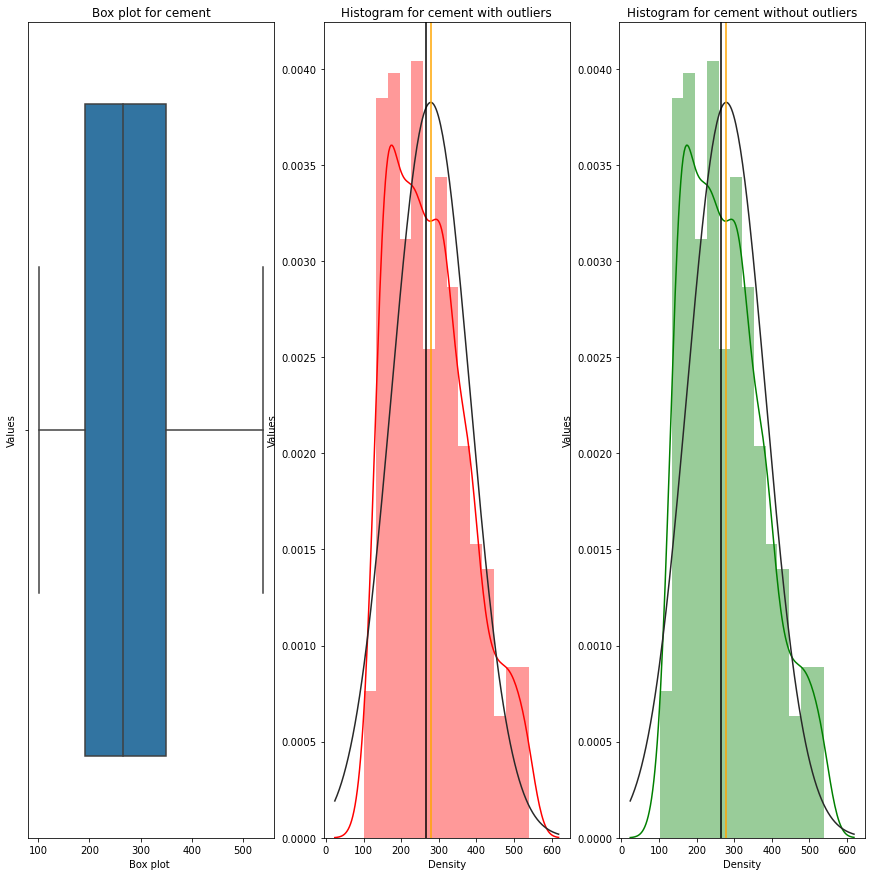

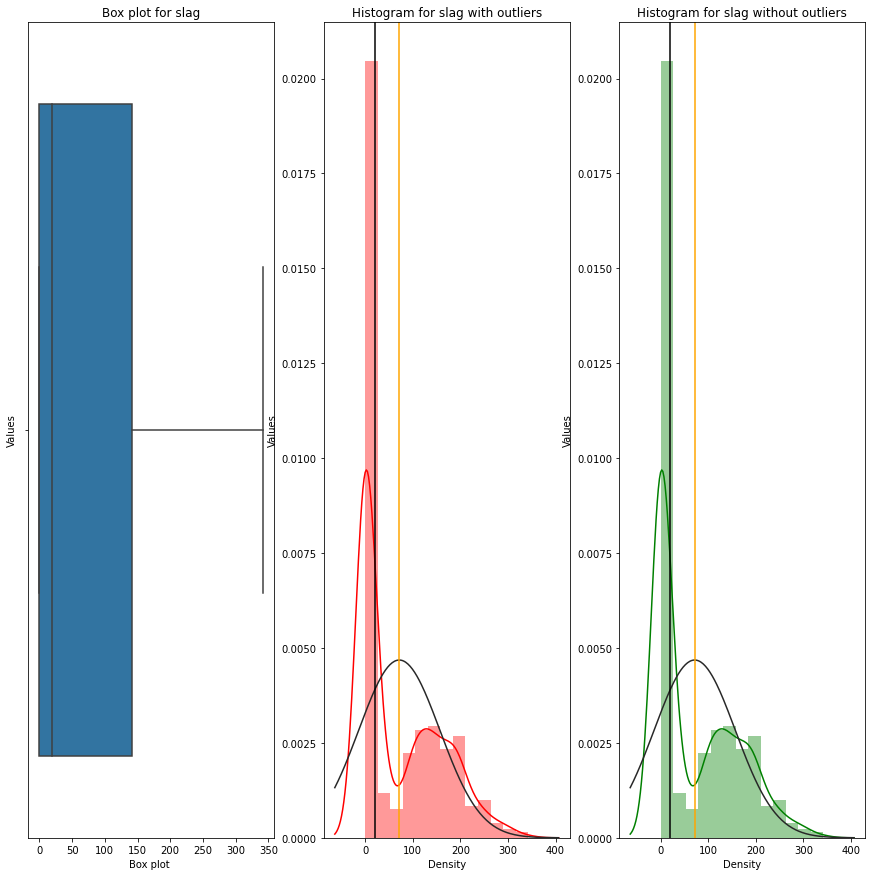

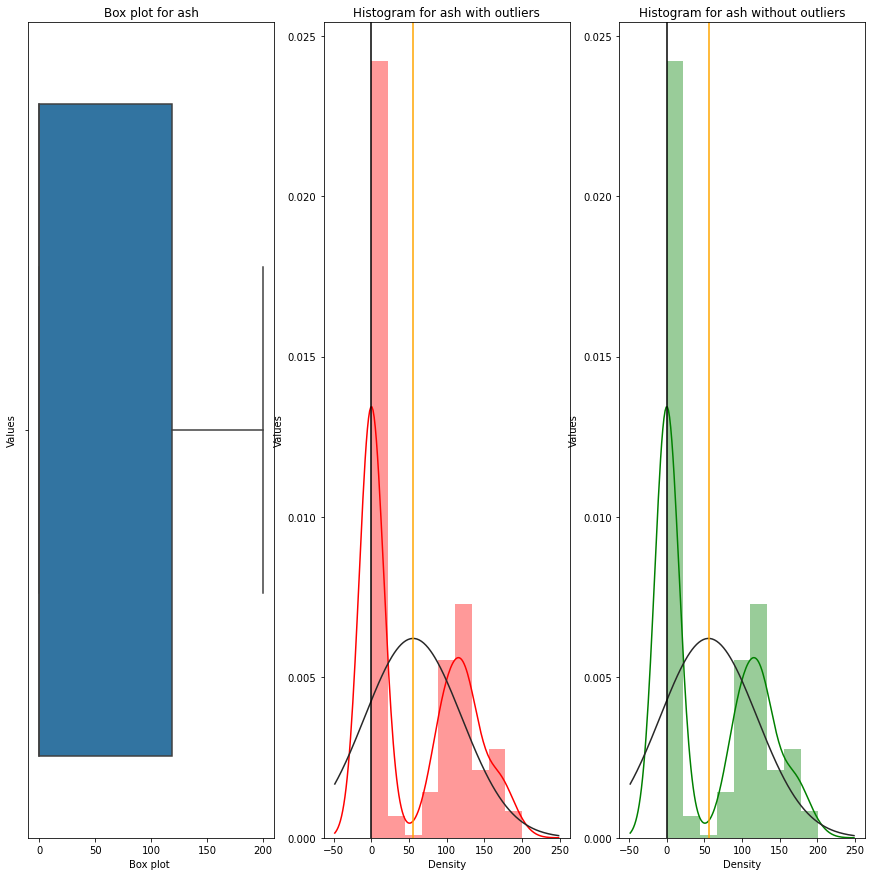

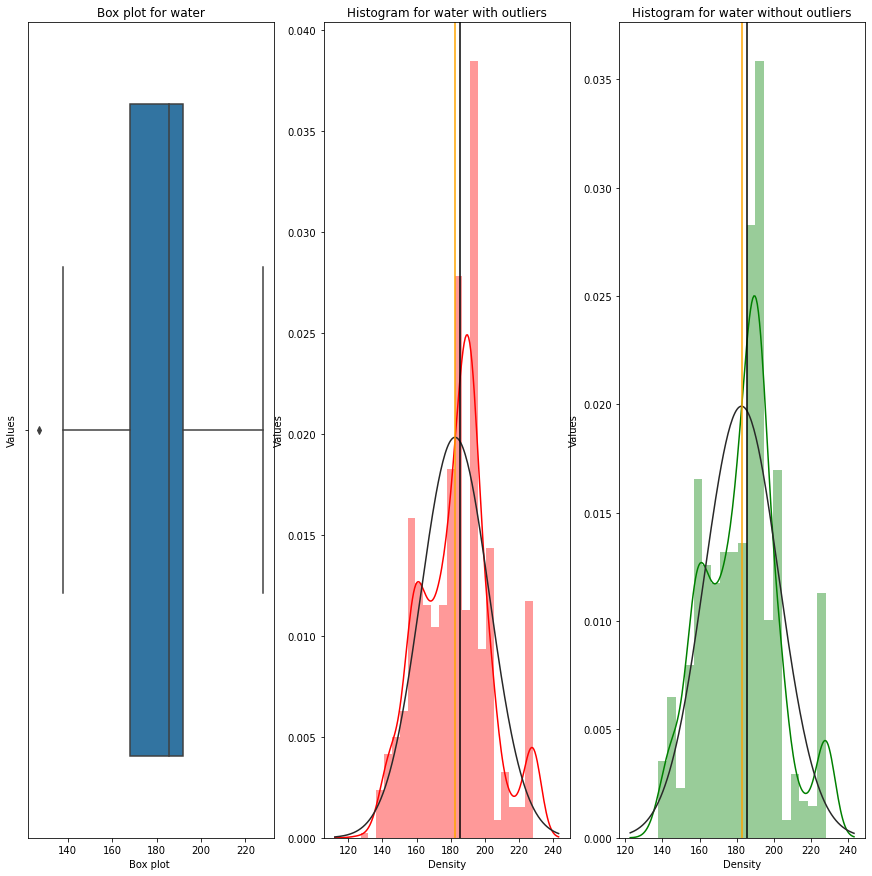

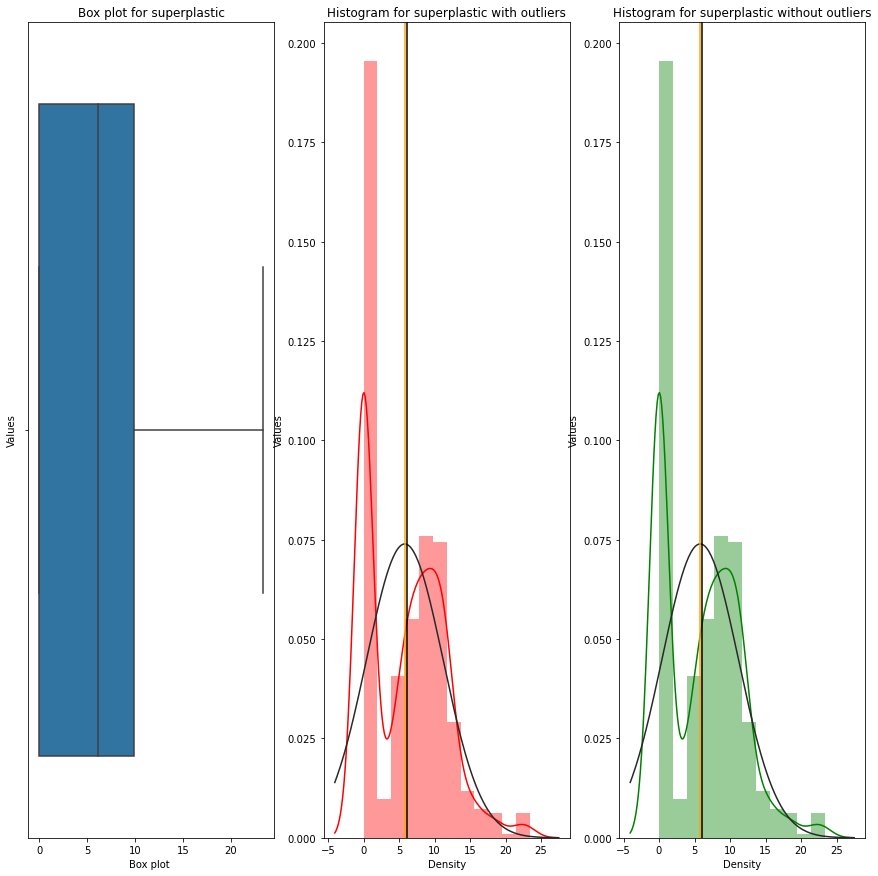

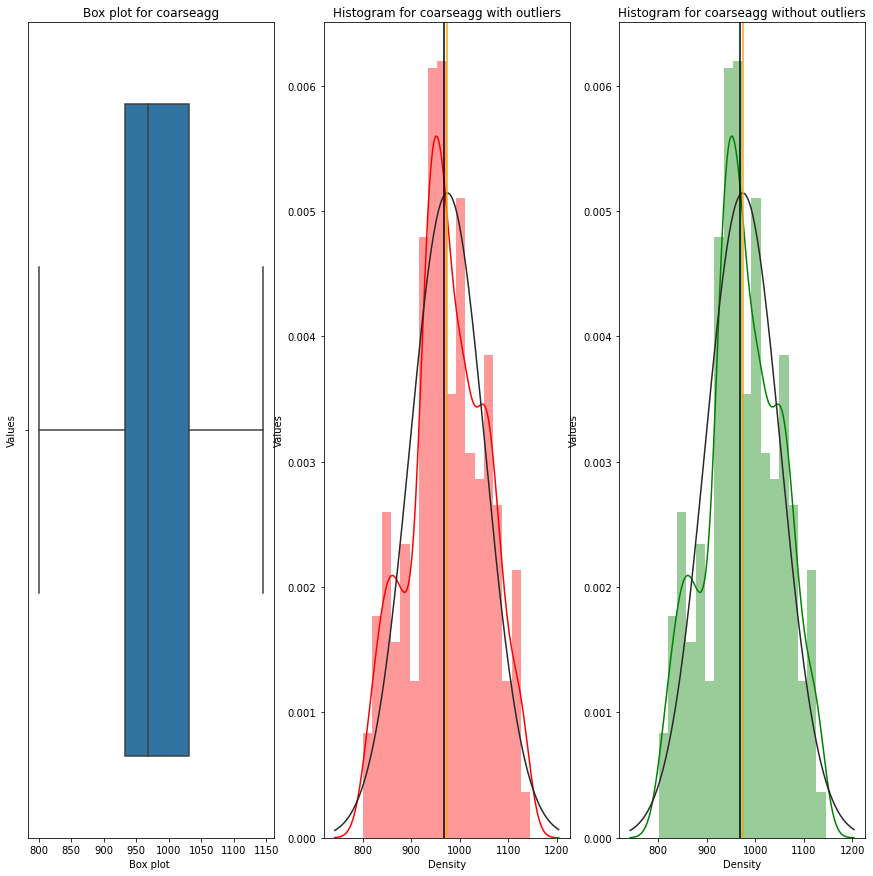

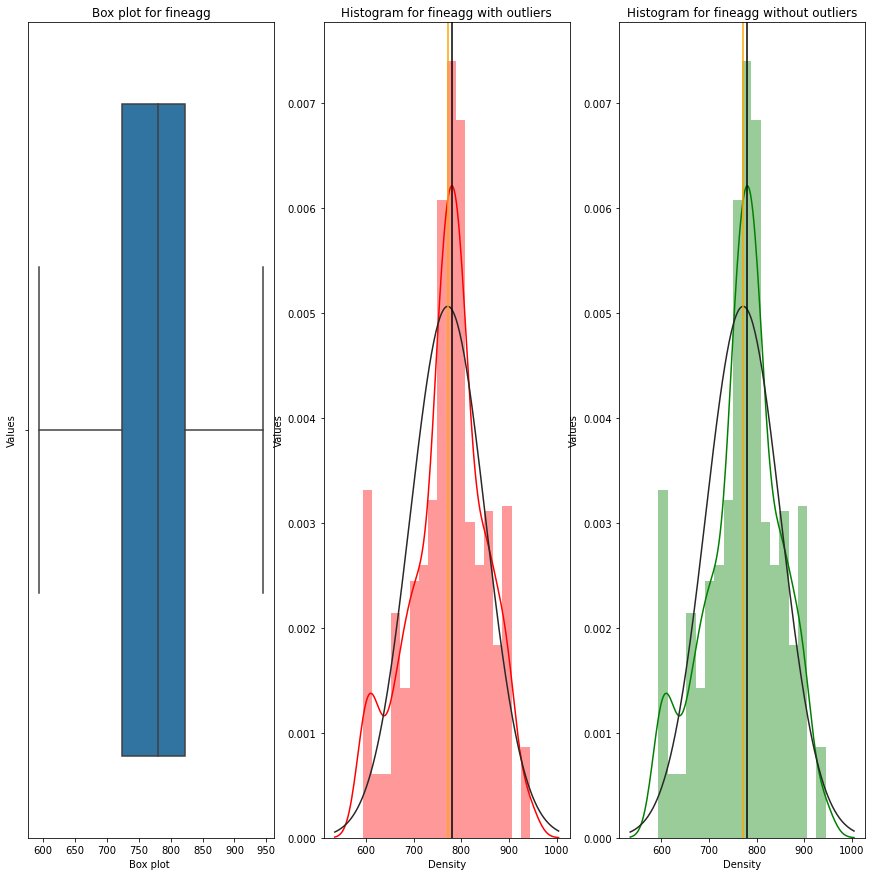

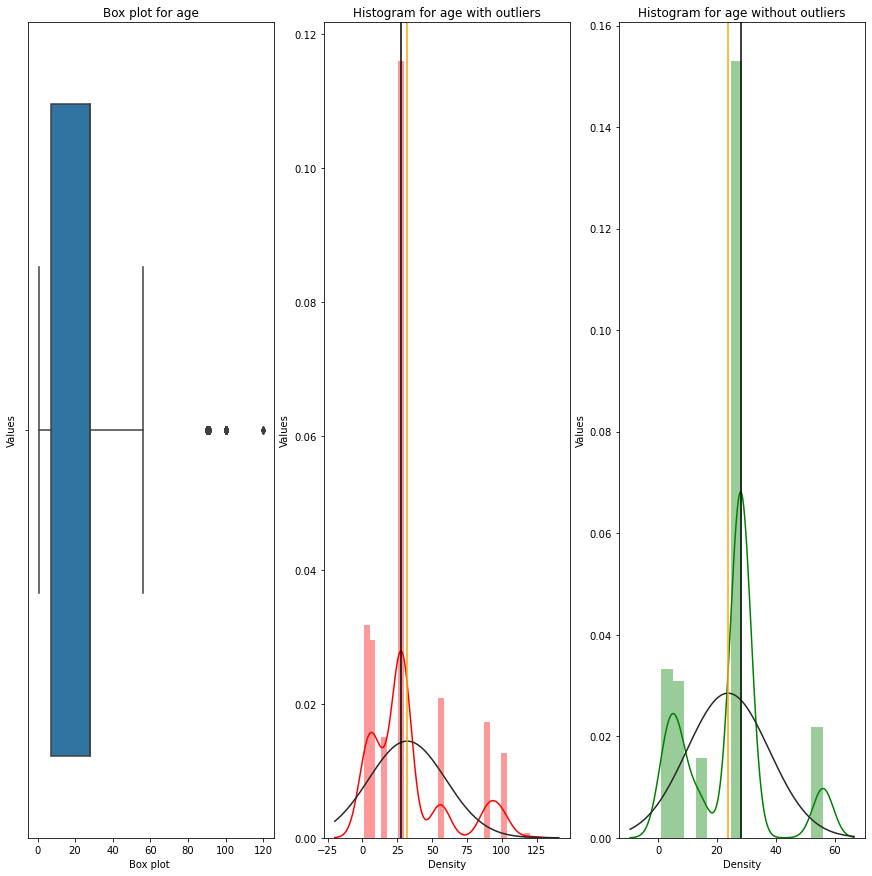

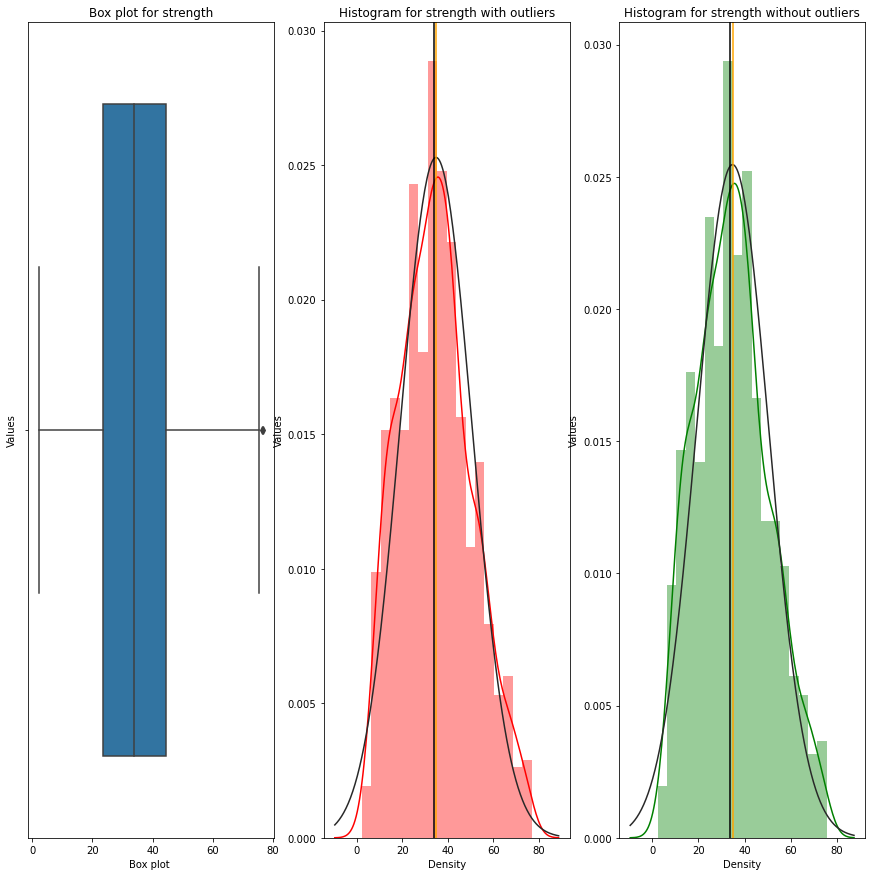

In [16]:
for col in df.columns:
    
    odt_plots(df,col)

In [17]:
# The outliers are replaced 
for col in df.columns:
    df = outlier_treatment(df,col)

column cement does not have any outliers
column slag does not have any outliers
column ash does not have any outliers
column water does not have any outliers
column superplastic does not have any outliers
column coarseagg does not have any outliers
column fineagg does not have any outliers
column age does not have any outliers
column strength does not have any outliers


## Performing Regression Analysis


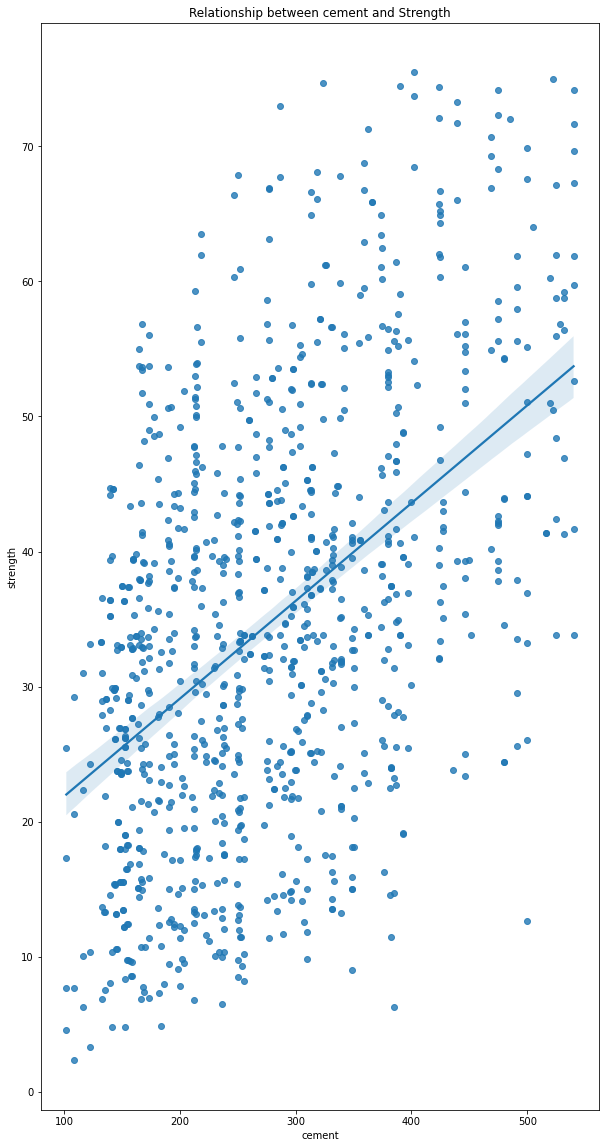

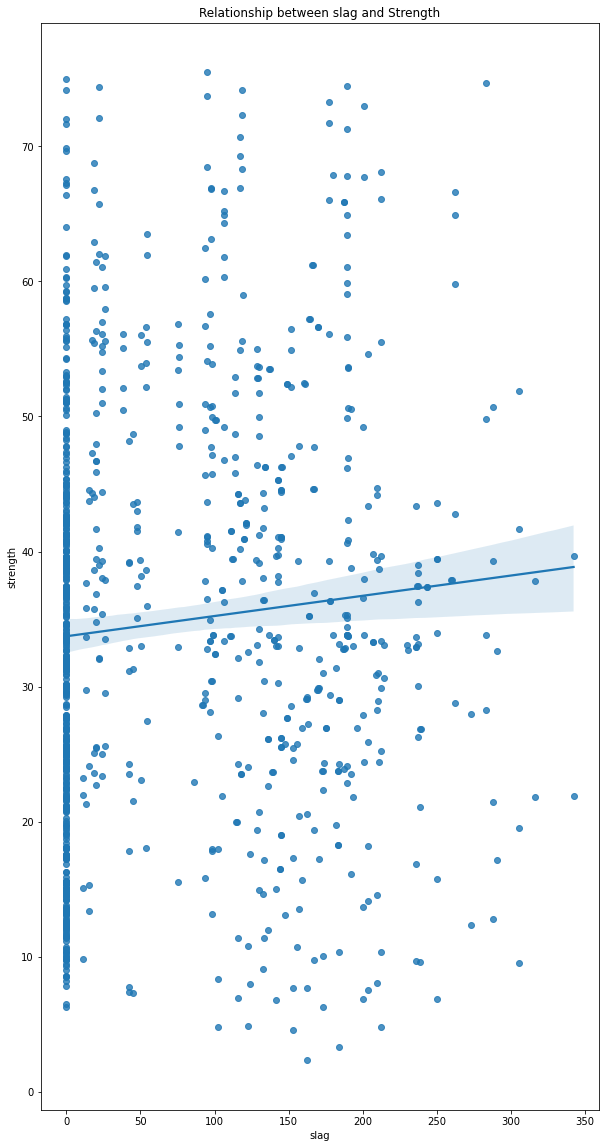

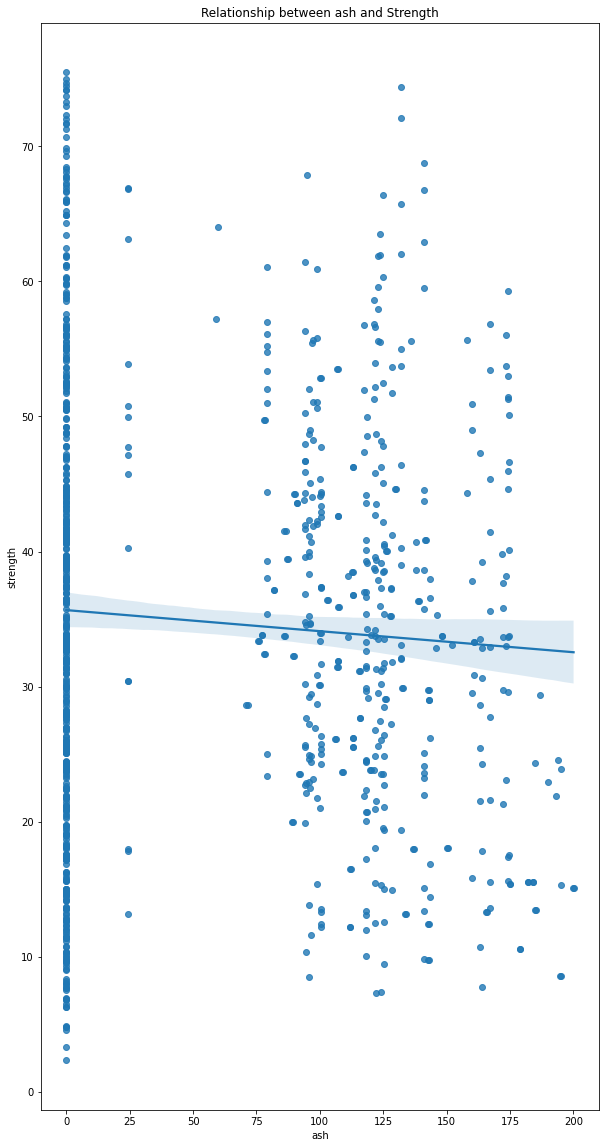

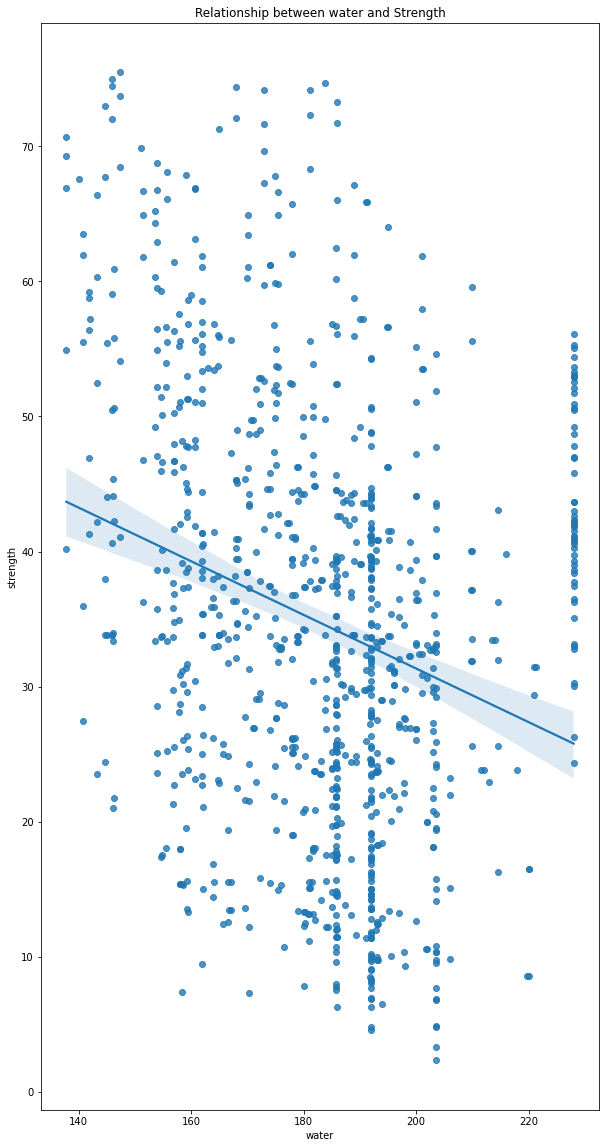

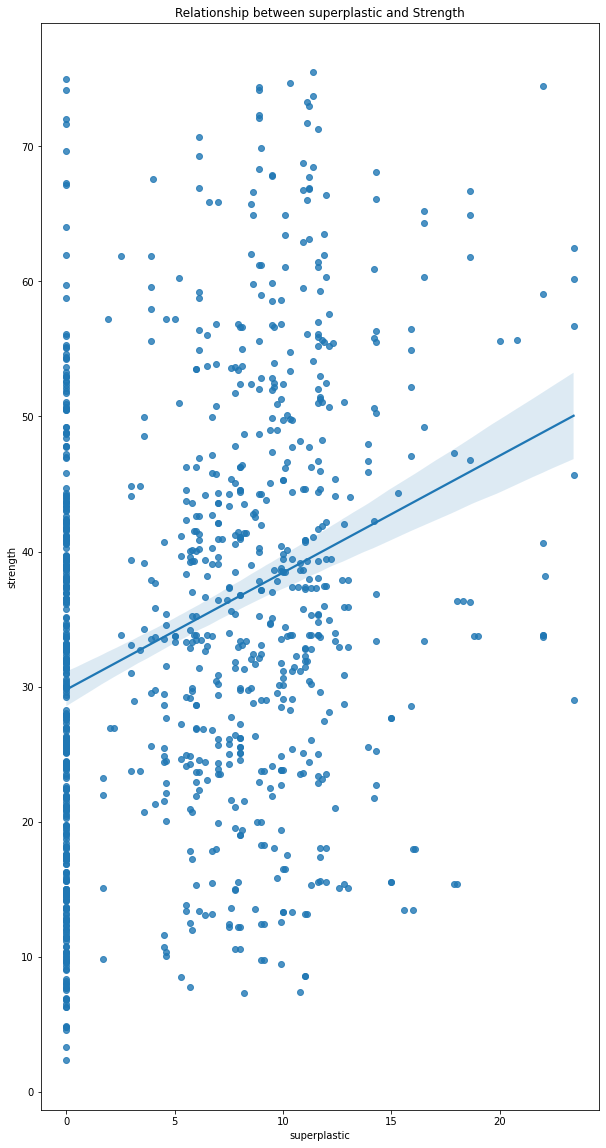

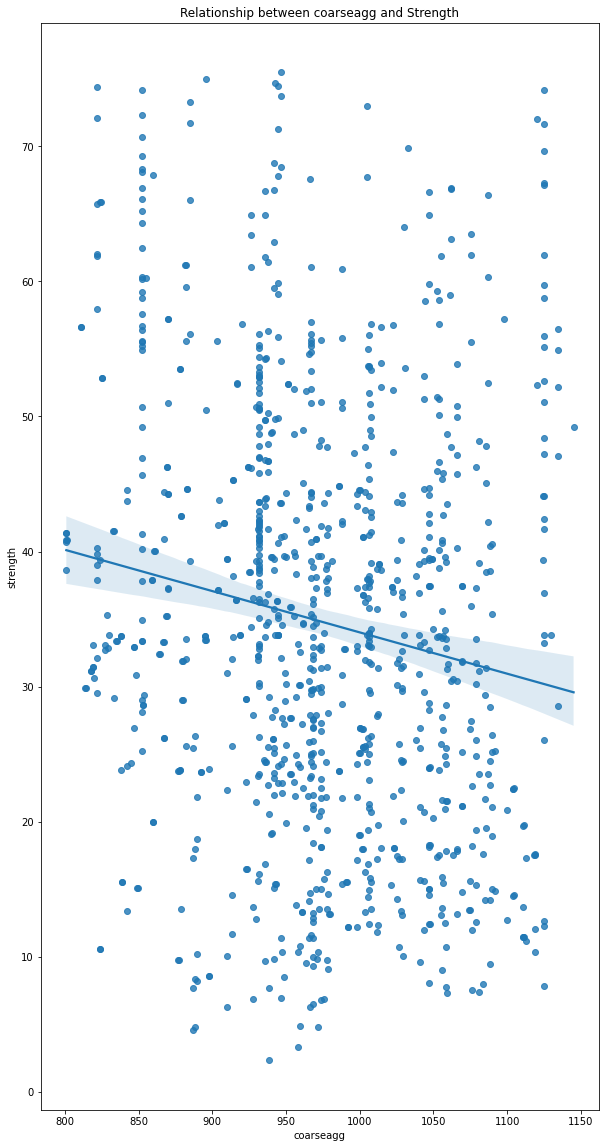

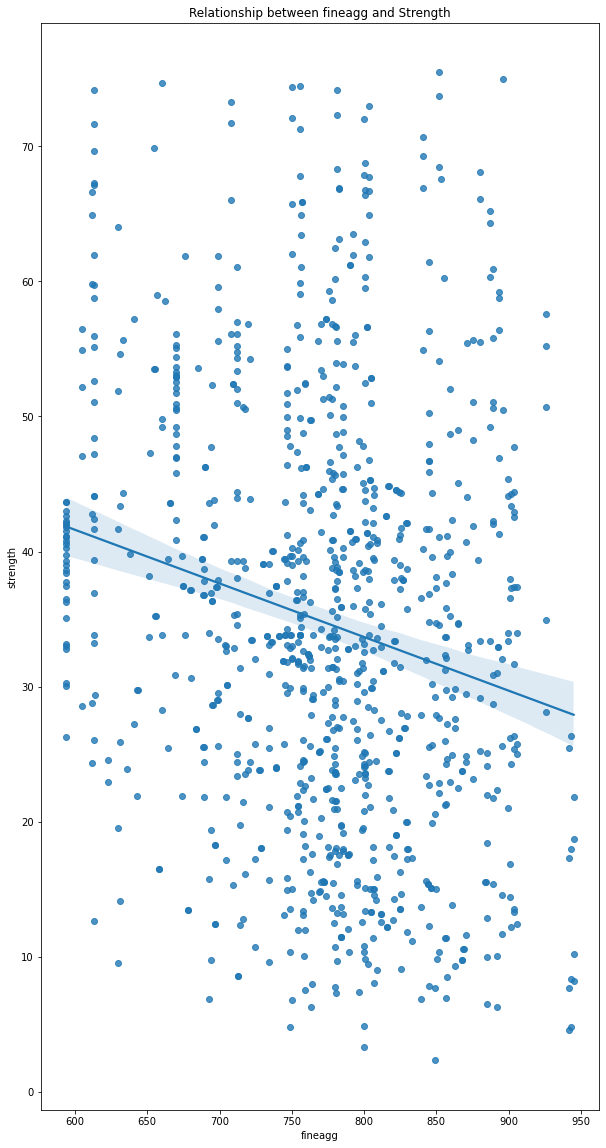

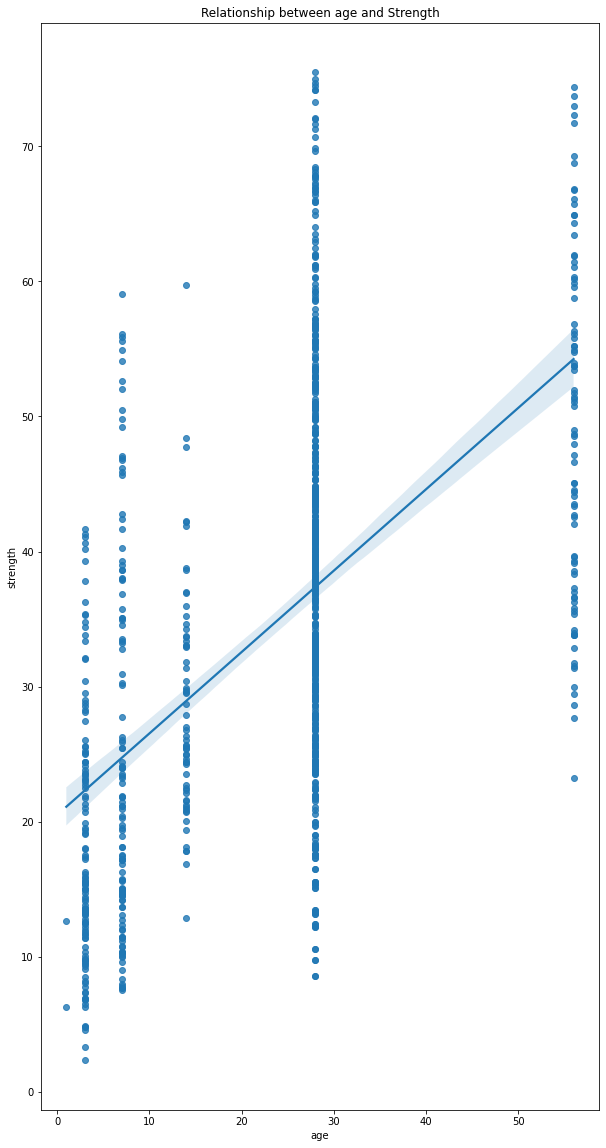

In [18]:

for col in df.columns:
    if col != "strength":
        
        f,ax = plt.subplots(figsize = (10,20))
        
        sns.regplot(x = df[col] , y = df["strength"]).set_title(f'Relationship between {col} and Strength')


In [19]:
#sns.regplot(x = df["cement"] , y = df["strength"])

In [20]:
# Positive Correlation - cement , slag , superplastic , age
# Negative Correlation - ash , water , coarseagg , fineagg
# No Correlation - 

## Finding out correlation with the target


In [21]:

def correlation_target(data , target_col):
    data_new = data.drop([target_col] , axis =1)
    indep_cols = data_new.columns
    
    correlation_result = []
    
    for col in indep_cols:
        correlation_result.append(data[target_col].corr(data[col]))
        
    # Transpose is used coz , dataframe has 2 columns, the correlation_result has 8 columns.
    
    result_df = pd.DataFrame([indep_cols,correlation_result] , index=["Variable","Correlation"]).T
    
    # print(indep_cols,correlation_result)
    
    return result_df.sort_values("Correlation" , ascending = False)

In [22]:
#df["strength"].corr(df["cement"])

In [23]:
correlation_target(df,"strength")

,Variable,Correlation
7,age,0.538574
0,cement,0.481818
4,superplastic,0.298341
1,slag,0.081518
2,ash,-0.063853
5,coarseagg,-0.151378
6,fineagg,-0.199586
3,water,-0.253747


In [24]:
# Correlation - age > cement > superplastic > water > fineagg > coarseagg > slag > ash

## Multicollinearity Check --> Heatmap

In [25]:
# FIRST LEVEL of proving Multicollinearity is through --> HEATMAP

<AxesSubplot:>

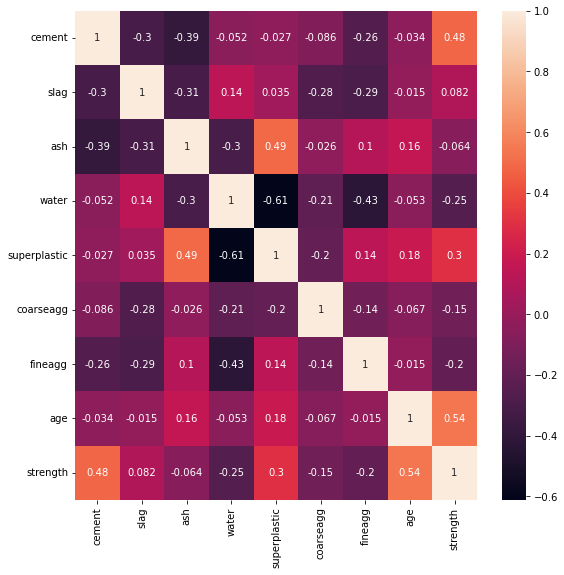

In [26]:
## To get the equations, we must check --- Multicollinearity 

corr = df.corr()
f,ax = plt.subplots(figsize =(9,9))
sns.heatmap(corr,annot = True)

# annot  = True--> displays the values

In [27]:
#corr = df.corr()
#corr

In [28]:
# In general if multicollinearity > 50% , we consider that the variables have correlation
# Here we are considering >30% (consider 30% too)

In [29]:
# Multicollinearity > 30% (including 30%)

# cement vs slag
# cement vs ash
# slag vs ash
# ash vs superplastic
# water vs ash
# superplastic vs water
# fineagg vs water

## Variance Inflation Factor

In [30]:
# SECOND LEVEL of proving Multicollinearity is through a formula or a statistical parameter--> VIF

# Multicollinearity check 2 - VIF

# 1 Another method to find out multicollinearity is Variance Inflation Factor (VIF)
# 2 Formula - VIF = 1/(1-r2_score)
# 3 In this , we regress every independent variable with all the other independent varibles and find out the r2_score.
# 4 We use this r2_score in the above VIF formula in order to check the VIF number.
# 5 If VIF > 5 . then we say that multicollinearity exists

In [31]:
def vif_factor(indep_var):
    vif_df = pd.DataFrame()
    vif_df["Features"] = indep_var.columns
    vif_df["VIF"]= [variance_inflation_factor(indep_var.values,i) for i in range(indep_var.shape[1]) ]

    return vif_df.sort_values("VIF" , ascending = False)

In [32]:
vif_factor(df.drop("strength" , axis  = 1))

,Features,VIF
5,coarseagg,86.289779
3,water,79.095022
6,fineagg,67.639713
0,cement,13.682820
4,superplastic,5.166794
2,ash,4.349037
7,age,4.056114
1,slag,3.166799


## Principal Component Analysis
### To remove Multicollinearity

In [33]:
# PCA is a decomposition technique
# Disadvantage of PCA --> The originality of the data gets lost

In [86]:
# Implementing PCA inorder to remove the multicollinearity

def pca_apply(x):
    
    col = []
    len_columns = len(x.columns)  
    
    from sklearn.preprocessing import StandardScaler
    
    x = StandardScaler().fit_transform(x)
    
    from sklearn.decomposition import PCA
    
    for i in range(1,len_columns):
        pca = PCA(n_components = i)
        p_component = pca.fit_transform(x)
        
# EVR ---> Explained Variance Ration( how much information each of the p_components is taking in)

        evr = np.cumsum(pca.explained_variance_ratio_)
        
        if evr[i-1] > 0.9:
            
            n_components = i
            break
            
    print(evr)
    
# Creating a DataFrame

    for i in range(1,n_components+1):
        
        col.append("pc_" + str(i))
        
        
    pca_df = pd.DataFrame(data = p_component , columns=col)
    
    return pca_df


In [87]:
x = df.drop("strength" , axis = 1)
y = df[["strength"]]

In [88]:
df_pca = pca_apply(x)

[0.27952664 0.46091045 0.61178131 0.74701754 0.86791701 0.96995775]


In [37]:
df_pca

,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6
0,1.692846,1.606397,-1.168932,-0.059845,0.134745,0.891710
1,-1.886438,-0.528990,-1.254991,-0.321152,1.219541,-0.355129
2,-0.832703,-0.261381,-0.478491,0.321900,-1.222801,-0.026238
3,2.651913,0.926840,-0.053065,-0.713876,-0.856156,-0.223176
4,0.744898,1.177626,-0.638554,-0.905383,1.292588,0.731219
...,...,...,...,...,...,...
1000,-1.918540,0.490881,-0.985539,-0.575022,-0.780014,-0.749713
1001,-0.729719,-1.694758,2.162369,3.059333,0.133955,-0.303078
1002,-0.555993,1.246900,0.754709,0.218404,-0.317153,-0.381296
1003,2.588588,0.034434,0.467343,-0.755102,-1.281957,-0.474470


In [38]:
df_pca.corr()

,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6
pc_1,1.000000e+00,-1.692592e-16,2.179982e-16,7.130660e-17,-9.013877e-19,2.305711e-17
pc_2,-1.692592e-16,1.000000e+00,-1.712891e-16,8.640412e-17,4.475937e-17,1.808739e-16
pc_3,2.179982e-16,-1.712891e-16,1.000000e+00,3.093534e-17,-1.472319e-17,3.872968e-17
pc_4,7.130660e-17,8.640412e-17,3.093534e-17,1.000000e+00,-3.563768e-17,7.082359e-16
pc_5,-9.013877e-19,4.475937e-17,-1.472319e-17,-3.563768e-17,1.000000e+00,2.037671e-16
pc_6,2.305711e-17,1.808739e-16,3.872968e-17,7.082359e-16,2.037671e-16,1.000000e+00


In [39]:
vif_factor(df_pca)

,Features,VIF
2,pc_3,1.0
1,pc_2,1.0
4,pc_5,1.0
5,pc_6,1.0
0,pc_1,1.0
3,pc_4,1.0


In [40]:
df_new = df_pca.join(df[["strength"]] , how = "left")
#df_new.dropna(inplace = True)

In [41]:
df_new

,pc_1,pc_2,pc_3,pc_4,pc_5,pc_6,strength
0,1.692846,1.606397,-1.168932,-0.059845,0.134745,0.891710,29.89
1,-1.886438,-0.528990,-1.254991,-0.321152,1.219541,-0.355129,23.51
2,-0.832703,-0.261381,-0.478491,0.321900,-1.222801,-0.026238,29.22
3,2.651913,0.926840,-0.053065,-0.713876,-0.856156,-0.223176,45.85
4,0.744898,1.177626,-0.638554,-0.905383,1.292588,0.731219,18.29
...,...,...,...,...,...,...,...
1000,-1.918540,0.490881,-0.985539,-0.575022,-0.780014,-0.749713,37.96
1001,-0.729719,-1.694758,2.162369,3.059333,0.133955,-0.303078,22.84
1002,-0.555993,1.246900,0.754709,0.218404,-0.317153,-0.381296,38.70
1003,2.588588,0.034434,0.467343,-0.755102,-1.281957,-0.474470,33.80


## Model Building - is done in 3 steps
### 1) Normal Model Building
### 2) Cross Validation
### 3) Hyper Parameter Tuning

In [42]:
# Function for train_test_split

def train_and_test_split(x,y,test_size = 0.3,random_state = 100):
    
    return  train_test_split(x,y,test_size = test_size,random_state = random_state)


In [43]:
def build_model(model,model_name,x,y):
    
    x_train,x_test,y_train,y_test = train_and_test_split(x,y)
    
    model.fit(x_train,y_train)
    
    y_pred = model.predict(x_test)
    
    r2score = r2_score(y_test,y_pred)
    
    rmse = np.sqrt(mean_squared_error(y_test,y_pred))
    
    temp = [model_name,r2score,rmse]
    
    return temp

In [44]:
build_model(LinearRegression(),"Linear Regression",df_pca,y)

['Linear Regression', 0.6376009262864732, 9.692600854231861]

In [45]:
def build_multiple_models(x,y):
    
    col_names = ["Model_Name" , "R2 Score" ,"RMSE"]
    
    result_df  = pd.DataFrame(columns = col_names)
    
    result_df.loc[len(result_df)] = build_model(LinearRegression(),"Linear Regression",x,y)
    result_df.loc[len(result_df)] = build_model(Lasso(),"Lasso ",x,y)
    result_df.loc[len(result_df)] = build_model(Ridge(),"Ridge ",x,y)
    result_df.loc[len(result_df)] = build_model(DecisionTreeRegressor(),"Decision Tree Regression",x,y)
    result_df.loc[len(result_df)] = build_model(KNeighborsRegressor(),"KNN Regression",x,y)
    result_df.loc[len(result_df)] = build_model(SVR(),"Support Vector Regression",x,y)
    result_df.loc[len(result_df)] = build_model(RandomForestRegressor(),"Random Forest Regression",x,y)
    result_df.loc[len(result_df)] = build_model(AdaBoostRegressor(),"AdaBoost Regression",x,y)
    result_df.loc[len(result_df)] = b(uild_model(GradientBoostingRegressor(),"GBoost Regression",x,y)
    result_df.loc[len(result_df)] = build_model(XGBRegressor(),"XGBoost Regression",x,y)

    
    
    return result_df.sort_values("R2 Score" ,ascending=False)

In [46]:
build_multiple_models(df_pca,y)

,Model_Name,R2 Score,RMSE
6,Random Forest Regression,0.768778,7.742149
8,GBoost Regression,0.745110,8.128747
9,XGBoost Regression,0.722004,8.489183
4,KNN Regression,0.713889,8.612196
7,AdaBoost Regression,0.684771,9.039823
0,Linear Regression,0.637601,9.692601
2,Ridge,0.637549,9.693297
3,Decision Tree Regression,0.636933,9.701525
1,Lasso,0.616377,9.972384
5,Support Vector Regression,0.574446,10.503266


## Performing Cross Validation

In [47]:
def cross_validation(x,y,fold = 10):
    
    score_lr = cross_val_score(LinearRegression(),x,y,cv = fold)
    score_ls = cross_val_score(Lasso(),x,y,cv = fold)
    score_rd = cross_val_score(Ridge(),x,y,cv = fold)
    score_dt = cross_val_score(DecisionTreeRegressor(),x,y,cv = fold)
    score_kn = cross_val_score(KNeighborsRegressor(),x,y,cv = fold)
    score_svr = cross_val_score(SVR(),x,y,cv = fold)
    score_rf = cross_val_score(RandomForestRegressor(),x,y,cv = fold)
    score_ad = cross_val_score(AdaBoostRegressor(),x,y,cv = fold)
    score_gb = cross_val_score(GradientBoostingRegressor(),x,y,cv = fold)
    score_xgb = cross_val_score(XGBRegressor(),x,y,cv = fold)
    
    score_list = [score_lr,score_ls,score_rd,score_dt,score_kn,score_svr,score_rf,score_ad,score_gb,score_xgb]
    
    model_names = ["Linear Regression" , "Lasso","Ridge","Decision Tree Regression","KNN Regression","Support Vector Regression","Random Forest Regression","AdaBoost Regression","GradientBoost Regression","XGBoost Regression"]
    
    
    result = []
    
    for i in range(0,len(model_names)):
        
        score_mean = np.mean(score_list[i])
        score_std = np.std(score_list[i])
        
        model = model_names[i]
        
        temp = [model , score_mean , score_std]
        
        result.append(temp)
        
    
    result_df = pd.DataFrame(result , columns = ["Model_Names" , "Accuracy","Standard Deviation"])
    
    return result_df.sort_values("Accuracy",ascending=False)

In [48]:
#cross_validation(df_pca,y)

In [49]:
# Hyper Parameter Tuning

def hyper_parameter_tuning(x,y,fold = 10):
    
    param_ls_rd = {'alpha':[1e-15,1e-13,1e-11,1e-9,1e-7,1e-5,1e-3,1e-1,1,2,3,4,5,6,7,8,9,10,20,30,40,450,60,70,80,90,100,200,300,400,500,]}
    
    param_kn = {"n_neighbors" : [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,25,30,35,40,45,50,55,60,65,70,75,80,85,90,95,100]}
    
    param_rf = {'n_estimators' : [10,20,30,40,50,60,70,80,90,110,130,150,170,190],'min_impurity_decrease':[0.0,0.5,1] , 'bootstrap' : [True,False]}
    
    param_ad = {"n_estimators" : [10,20,30,40,50,60,70,80,90,110,130,150,170,190] , "learning_rate" : [0.001,0.01,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,10]}
    
    param_gb = {'alpha' : [0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1],'learning_rate':[0.001,0.01,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1]}
    
    param_xgbr = {'learning_rate' : [0.01,0.1,0.5],'gamma':[0.5,0.6,0.7,0.8,0.9,1],'reg_lambda':[0.5,0.6,0.7,0.8,0.9,1]}
    
    tune_ls = GridSearchCV(Lasso(),param_ls_rd,cv = fold)
    tune_rd = GridSearchCV(Ridge(),param_ls_rd,cv = fold)
    tune_kn = GridSearchCV(KNeighborsRegressor(),param_kn,cv = fold)
    tune_rf = GridSearchCV(RandomForestRegressor(),param_rf,cv = fold)
    tune_ad = GridSearchCV(AdaBoostRegressor(),param_ad,cv = fold)
    tune_gb = GridSearchCV(GradientBoostingRegressor(),param_gb,cv = fold)
    tune_xgbr = GridSearchCV(XGBRegressor(),param_xgbr,cv = fold)
    
    tune_ls.fit(x,y)
    tune_rd.fit(x,y)
    tune_kn.fit(x,y)
    tune_rf.fit(x,y)
    tune_ad.fit(x,y)
    tune_gb.fit(x,y)
    tune_xgbr.fit(x,y)

    tuned = [tune_ls,tune_rd,tune_kn,tune_rf,tune_ad,tune_gb,tune_xgbr]
    
    models = ["Lasso","Ridge","KNN Regression","Random Forest Regression","AdaBoost Regression","GradientBoost Regression","XGBoost Regression"]
    
    for i in range(0,len(models)):
        
        print(models[i])
        
        print("Best Params" , tuned[i].best_params_)

In [50]:
#hyper_parameter_tuning(df_pca,y)

In [51]:
def cross_validation_tuned(x,y,fold = 10):
    
    score_lr = cross_val_score(LinearRegression(),x,y,cv = fold)
    score_ls = cross_val_score(Lasso(alpha = 2),x,y,cv = fold)
    score_rd = cross_val_score(Ridge(alpha = 500),x,y,cv = fold)
    score_dt = cross_val_score(DecisionTreeRegressor(),x,y,cv = fold)
    score_kn = cross_val_score(KNeighborsRegressor(n_neighbors=4),x,y,cv = fold)
    score_svr = cross_val_score(SVR(),x,y,cv = fold)
    score_rf = cross_val_score(RandomForestRegressor(bootstrap=True , min_impurity_decrease=0.0 , n_estimators = 130),x,y,cv = fold)
    score_ad = cross_val_score(AdaBoostRegressor(learning_rate=0.4 , n_estimators=90),x,y,cv = fold)
    score_gb = cross_val_score(GradientBoostingRegressor(alpha=0.1 , learning_rate=0.2),x,y,cv = fold)
    score_xgb = cross_val_score(XGBRegressor(gamma = 0.8 , learning_rate=0.1 , reg_lambda = 1),x,y,cv = fold)
    
    score_list = [score_lr,score_ls,score_rd,score_dt,score_kn,score_svr,score_rf,score_ad,score_gb,score_xgb]
    
    model_names = ["Linear Regression" , "Lasso","Ridge","Decision Tree Regression","KNN Regression","Support Vector Regression","Random Forest Regression","AdaBoost Regression","GradientBoost Regression","XGBoost Regression"]
    
    
    result = []
    
    for i in range(0,len(model_names)):
        
        score_mean = np.mean(score_list[i])
        score_std = np.std(score_list[i])
        
        model = model_names[i]
        
        temp = [model , score_mean , score_std]
        
        result.append(temp)
        
    
    result_df = pd.DataFrame(result , columns = ["Model_Names" , "Accuracy","Standard Deviation"])
    
    return result_df.sort_values("Accuracy",ascending=False)

In [52]:
cross_validation_tuned(df_pca,y)

,Model_Names,Accuracy,Standard Deviation
6,Random Forest Regression,0.772655,0.047683
9,XGBoost Regression,0.761453,0.054538
8,GradientBoost Regression,0.753951,0.042503
4,KNN Regression,0.731701,0.052420
7,AdaBoost Regression,0.661568,0.036142
3,Decision Tree Regression,0.654347,0.093308
5,Support Vector Regression,0.651091,0.052301
0,Linear Regression,0.628632,0.058045
1,Lasso,0.569674,0.054918
2,Ridge,0.557343,0.052166


## Performing K-means Clustering

In [53]:
# Clustering

from sklearn.cluster import KMeans

In [54]:
# Using the backup data without dropping duplicates

for col in df_bkp:
    df_bkp = outlier_treatment(df_bkp,col)

column cement does not have any outliers
column slag has outliers and they are  918    359.4
990    359.4
Name: slag, dtype: float64
column ash does not have any outliers
column water has outliers and they are  66     247.0
263    246.9
432    121.8
462    121.8
587    121.8
740    237.0
789    121.8
826    236.7
914    121.8
Name: water, dtype: float64
column superplastic has outliers and they are  44      28.2
156     28.2
232     32.2
292     32.2
538     28.2
744     32.2
816     32.2
838     28.2
955     32.2
1026    28.2
Name: superplastic, dtype: float64
column coarseagg does not have any outliers
column fineagg has outliers and they are  129    992.6
447    992.6
504    992.6
584    992.6
857    992.6
Name: fineagg, dtype: float64
column age has outliers and they are  51      180
64      365
93      180
99      180
103     180
133     365
144     180
149     270
152     180
157     360
159     365
198     365
199     180
207     180
256     270
262     270
270     270
297     2

In [55]:
x = df_bkp.drop('strength',axis=1)
y = df_bkp[['strength']]

In [56]:
cluster = KMeans(n_clusters=2 , random_state=100)

In [57]:
labels = cluster.fit_predict(x)

In [58]:
labels

array([0, 0, 0, ..., 0, 1, 1])

<AxesSubplot:xlabel='cement', ylabel='strength'>

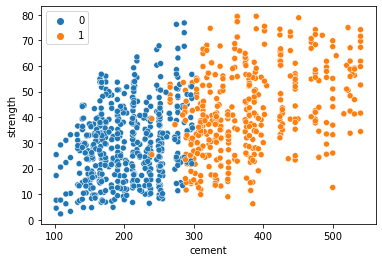

In [59]:
sns.scatterplot(x = x.cement , y = y.strength ,hue = labels)

<AxesSubplot:xlabel='slag', ylabel='strength'>

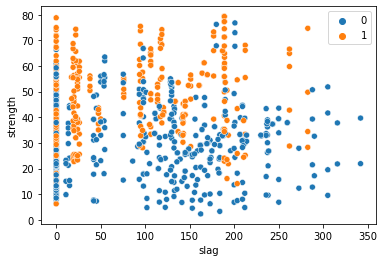

In [60]:
sns.scatterplot(x = x.slag , y = y.strength ,hue = labels)

<AxesSubplot:xlabel='age', ylabel='strength'>

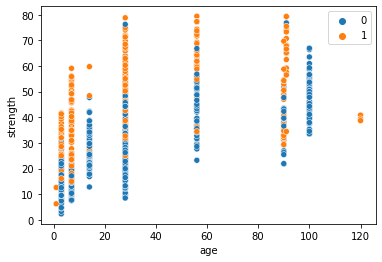

In [61]:
sns.scatterplot(x = x.age , y = y.strength ,hue = labels)

In [62]:

# r = no of rows

def kmeans_clustering(df,t_col,labels):
    
    columns = df.columns
    r = int(len(df.columns)/2)
    
    if r%2 == 0:
        r = r
    else:   
        r = r + 1
        
    figure,axis = plt.subplots(r,2,figsize = (15,15))
    a = 0 
    for row in range(0,r):
        for col in range(0,2): 
            if a != len(df.columns):
                axis[row][col].scatter(df[t_col] , df[columns[a]] , c = labels)
                axis[row][col].set_xlabel(t_col)
                axis[row][col].set_ylabel(columns[a])
                    
                a = a + 1

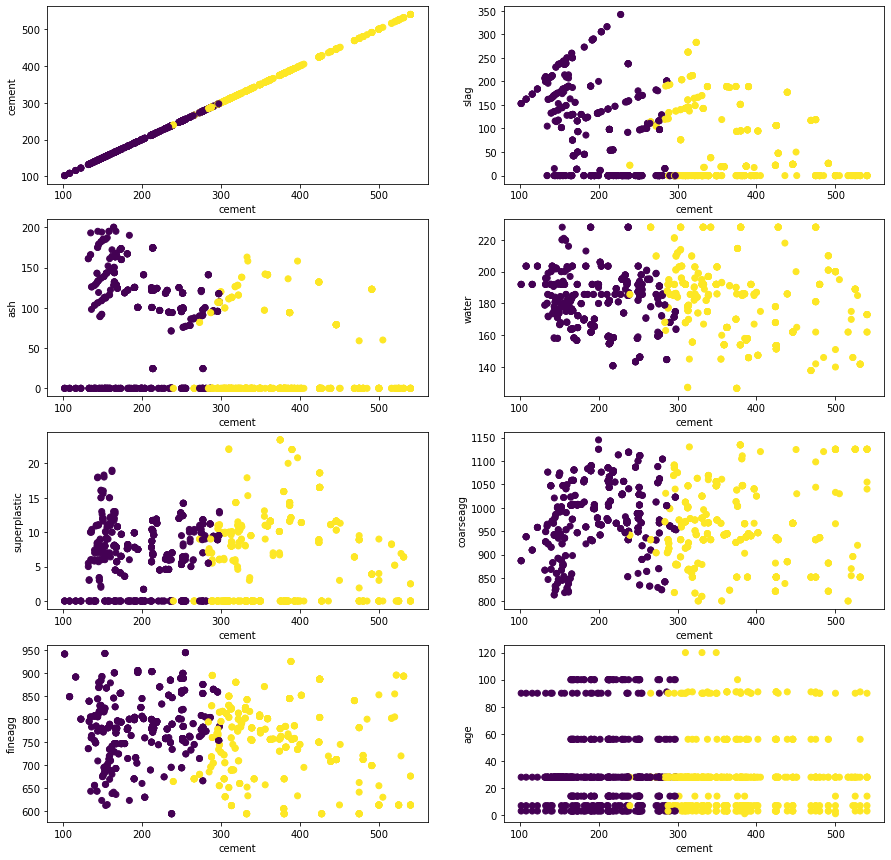

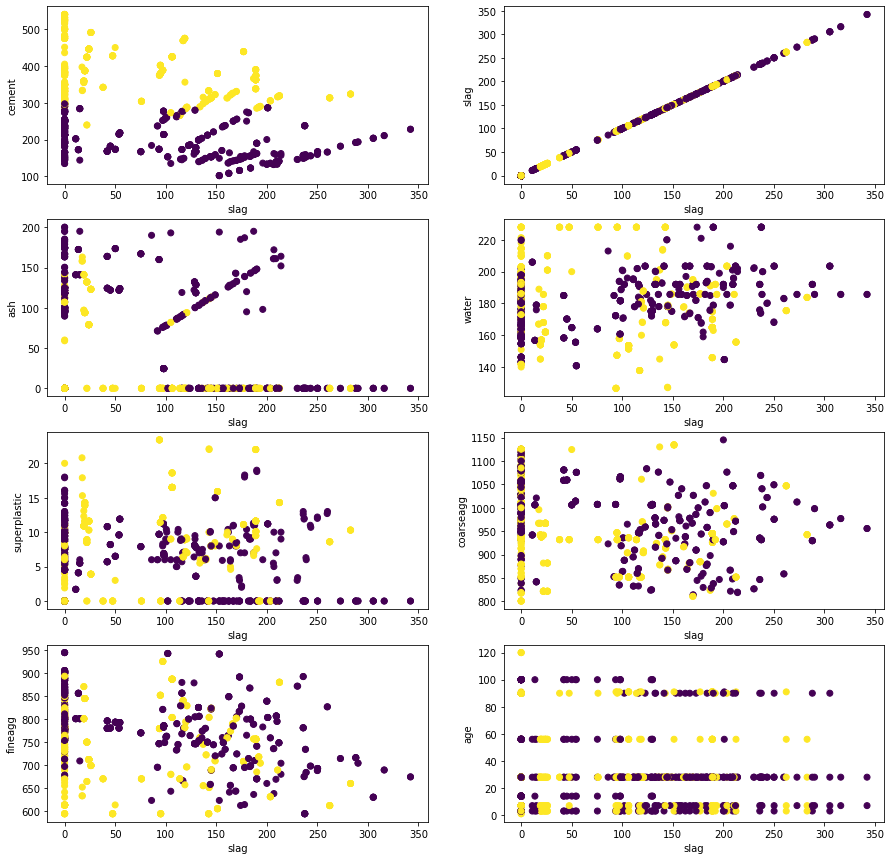

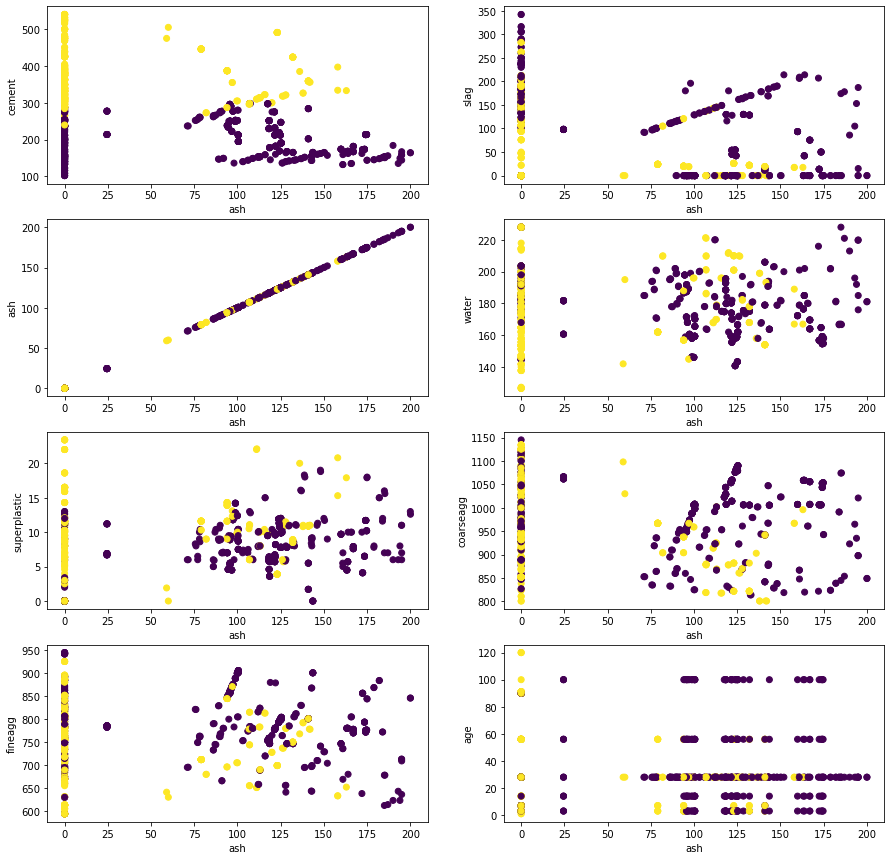

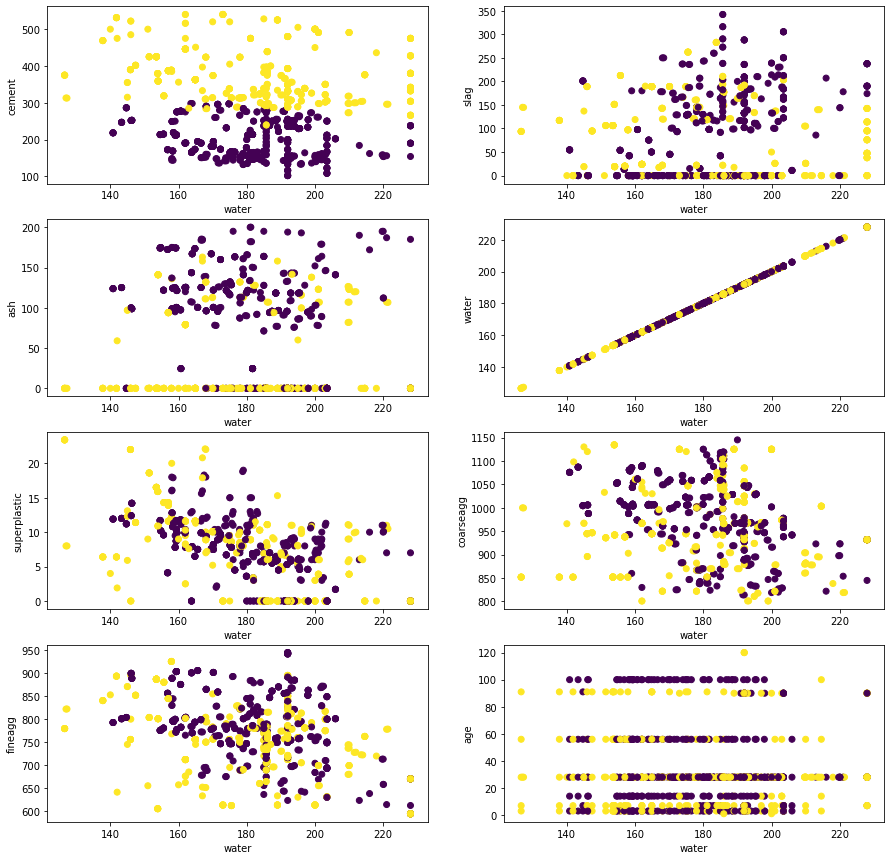

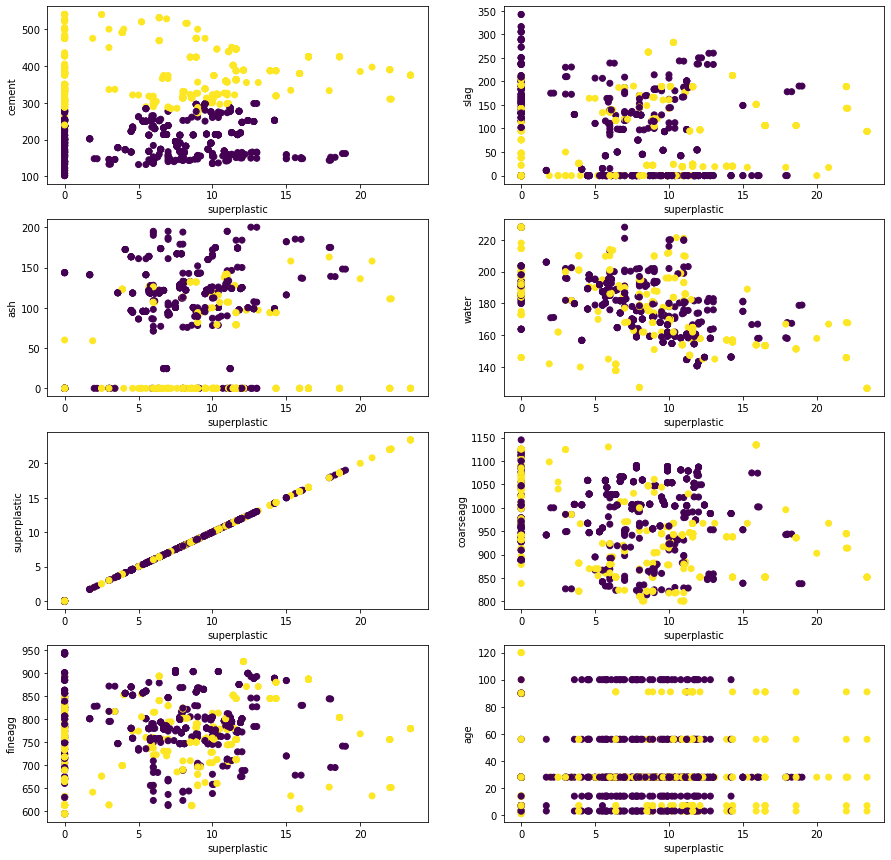

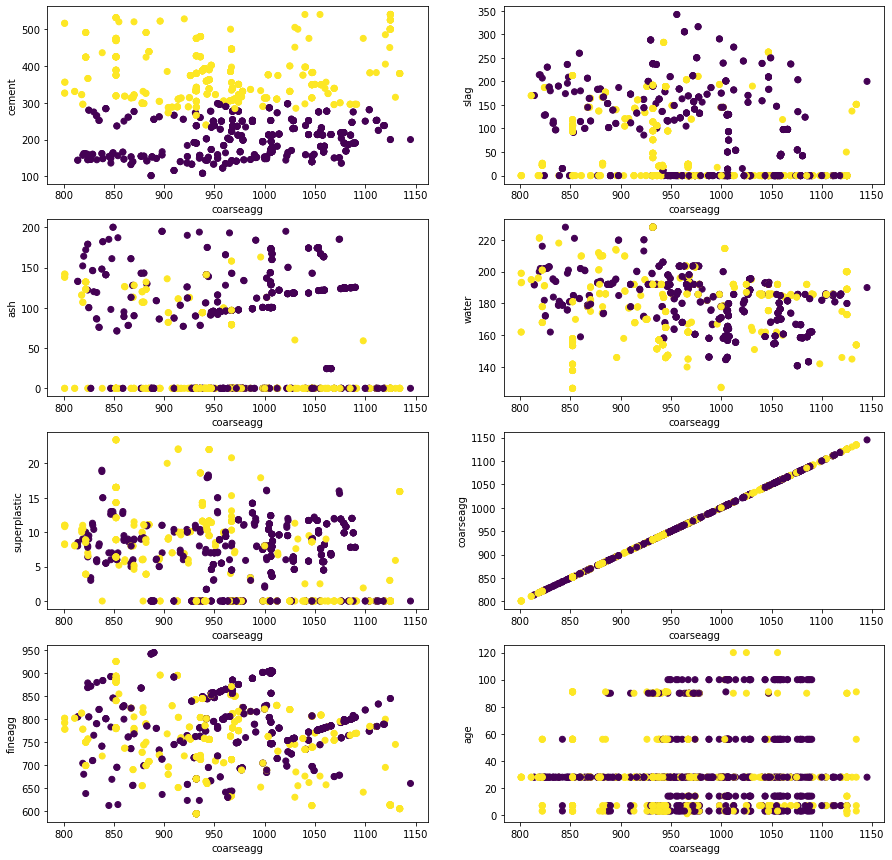

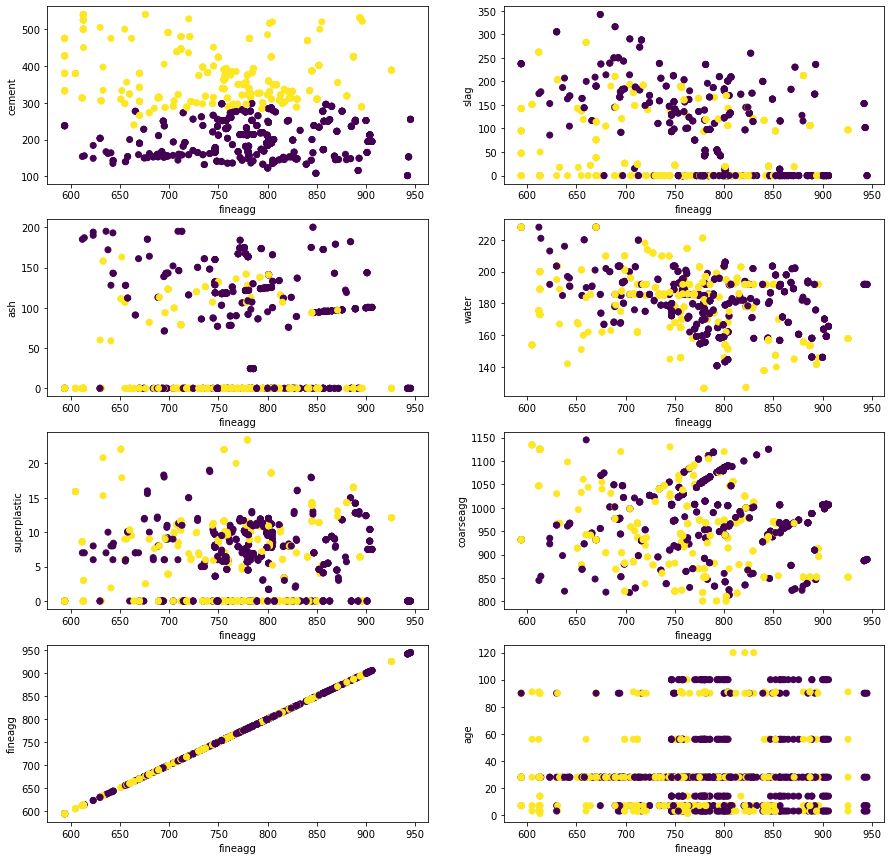

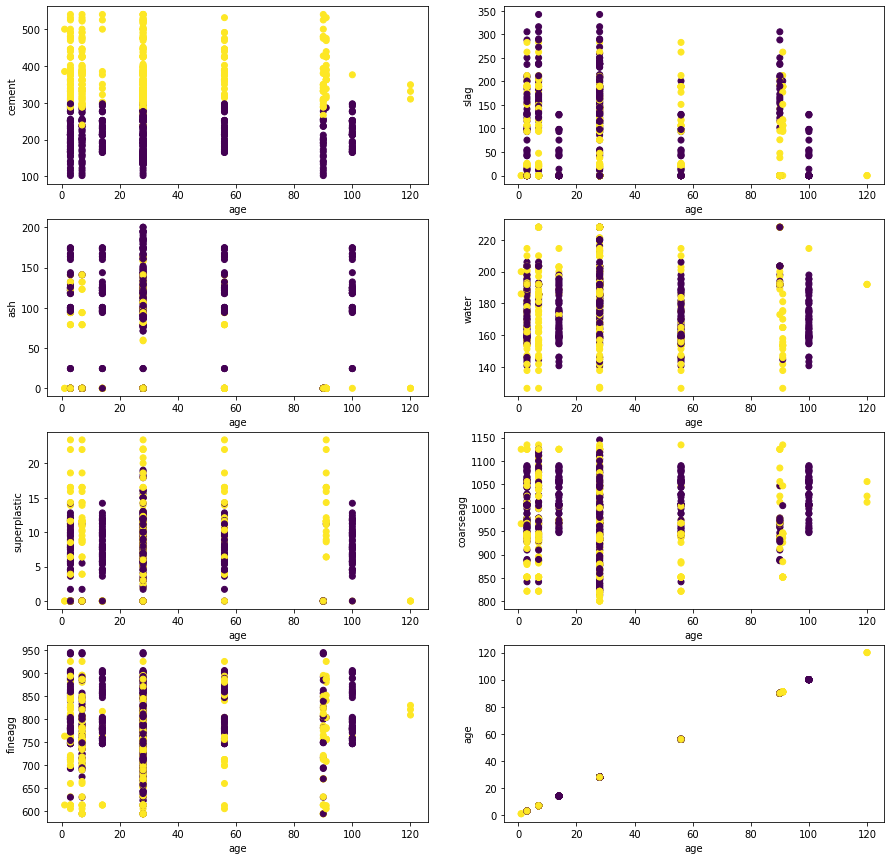

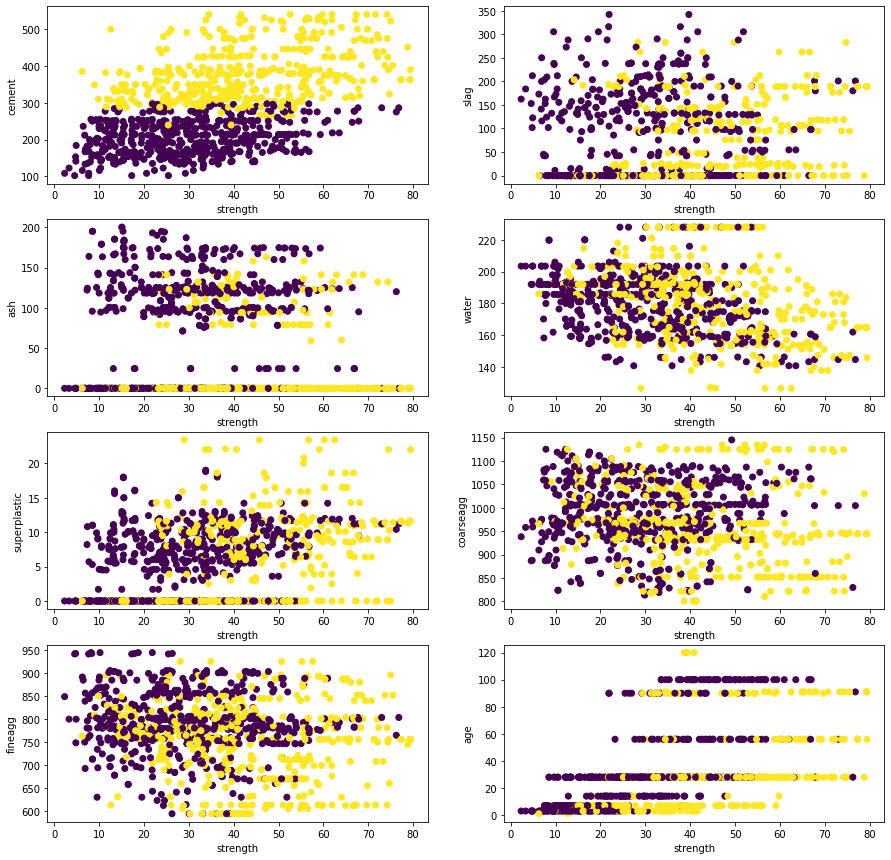

In [63]:
for col in df.columns:
    
    kmeans_clustering(df_bkp,col,labels)

In [64]:
# Cluster Anaysis:

# slag vs cement
# ash vs cement
# water vs cement
# superplastic vs cement
# coarseagg vs cement
# fineagg vs cement
# cement vs strength


In [65]:
labels_df = pd.DataFrame(labels , columns = ["Labels"])

In [66]:
new_df = df_bkp.join(labels_df , how = "left")

In [67]:
new_df

,cement,slag,ash,water,superplastic,coarseagg,fineagg,age,strength,Labels
0,141.3,212.0,0.0,203.5,0.0,971.8,748.5,28,29.89,0
1,168.9,42.2,124.3,158.3,10.8,1080.8,796.2,14,23.51,0
2,250.0,0.0,95.7,187.4,5.5,956.9,861.2,28,29.22,0
3,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.85,1
4,154.8,183.4,0.0,193.3,9.1,1047.4,696.7,28,18.29,0
...,...,...,...,...,...,...,...,...,...,...
1025,135.0,0.0,166.0,180.0,10.0,961.0,805.0,28,13.29,0
1026,531.3,0.0,0.0,141.8,6.4,852.1,893.7,3,41.30,1
1027,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28,0
1028,342.0,38.0,0.0,228.0,0.0,932.0,670.0,28,55.06,1


In [68]:
# duplicates should be dropped in EDA
# dont drop duplicates in clustering

In [69]:
x = new_df.drop('strength',axis=1)
y = new_df[['strength']]

In [70]:
cross_validation(x,y)

,Model_Names,Accuracy,Standard Deviation
9,XGBoost Regression,0.899436,0.046856
6,Random Forest Regression,0.888449,0.035062
8,GradientBoost Regression,0.875631,0.044913
3,Decision Tree Regression,0.837976,0.055194
7,AdaBoost Regression,0.751376,0.033122
1,Lasso,0.686684,0.062488
2,Ridge,0.686647,0.062316
0,Linear Regression,0.686640,0.062314
4,KNN Regression,0.668248,0.085736
5,Support Vector Regression,0.223931,0.038833


## Feature Importance

In [71]:
x_train,x_test,y_train,y_test = train_and_test_split(x,y,test_size=0.2,random_state=50)

In [72]:
xgb = XGBRegressor()
xgb.fit(x_train,y_train)

XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1,
             colsample_bynode=1, colsample_bytree=1, enable_categorical=False,
             gamma=0, gpu_id=-1, importance_type=None,
             interaction_constraints='', learning_rate=0.300000012,
             max_delta_step=0, max_depth=6, min_child_weight=1, missing=nan,
             monotone_constraints='()', n_estimators=100, n_jobs=8,
             num_parallel_tree=1, predictor='auto', random_state=0, reg_alpha=0,
             reg_lambda=1, scale_pos_weight=1, subsample=1, tree_method='exact',
             validate_parameters=1, verbosity=None)

<AxesSubplot:title={'center':'Feature importance'}, xlabel='F score', ylabel='Features'>

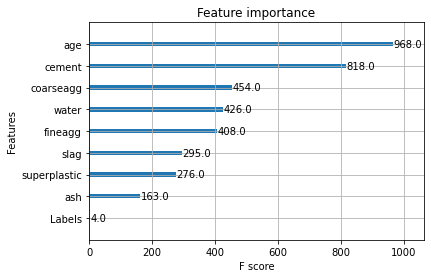

In [73]:
xgboost.plot_importance(xgb)

In [74]:
X = new_df[['age','cement','coarseagg','water','fineagg','slag']]
y = new_df[['strength']]

In [75]:
cross_validation(x,y)

,Model_Names,Accuracy,Standard Deviation
9,XGBoost Regression,0.899436,0.046856
6,Random Forest Regression,0.888061,0.033603
8,GradientBoost Regression,0.875581,0.044986
3,Decision Tree Regression,0.826800,0.051568
7,AdaBoost Regression,0.744597,0.033343
1,Lasso,0.686684,0.062488
2,Ridge,0.686647,0.062316
0,Linear Regression,0.686640,0.062314
4,KNN Regression,0.668248,0.085736
5,Support Vector Regression,0.223931,0.038833


## Learning Curve Analysis

In [76]:
def generic_lc(model_name, estimator, x, y):
    
    train_size,train_score,test_score = learning_curve(estimator, x, y, cv=10)
    
    train_score = np.mean(train_score, axis=1)
    test_score = np.mean(test_score, axis=1)
    
    plt.plot(train_size,train_score,color="blue")
    plt.plot(train_size,test_score,color="orange")
    
    plt.xlabel('Samples')
    plt.ylabel('Accuracy')
    plt.title('Learning Curve Analysis of ' + model_name)
    
    plt.legend(['Train Score','Test Score'])
    
    return train_size,train_score,test_score

In [77]:
x = new_df.drop('strength',axis=1)
y = new_df[['strength']]

(array([ 92, 301, 509, 718, 927]),
 array([0.94462461, 0.97740625, 0.97775935, 0.97910079, 0.9795758 ]),
 array([0.62947652, 0.81723143, 0.86510144, 0.87058101, 0.88832084]))

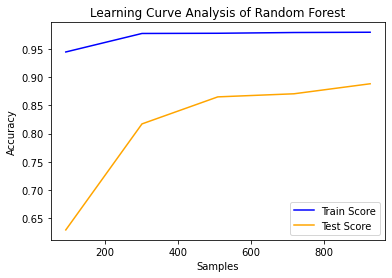

In [78]:
generic_lc("Random Forest",RandomForestRegressor(),x,y)

(array([ 92, 301, 509, 718, 927]),
 array([0.99969628, 0.99758022, 0.9928369 , 0.99207633, 0.99121044]),
 array([0.64715047, 0.83220276, 0.87966735, 0.88045784, 0.89943565]))

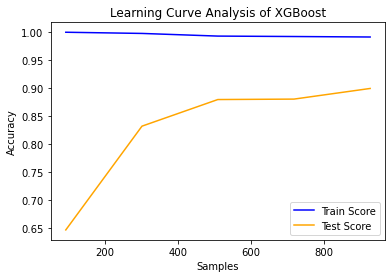

In [79]:
generic_lc("XGBoost",XGBRegressor(),x,y)

(array([ 92, 301, 509, 718, 927]),
 array([0.99210371, 0.96620205, 0.949049  , 0.94274014, 0.9320328 ]),
 array([0.67643691, 0.84237528, 0.8591453 , 0.86722441, 0.875419  ]))

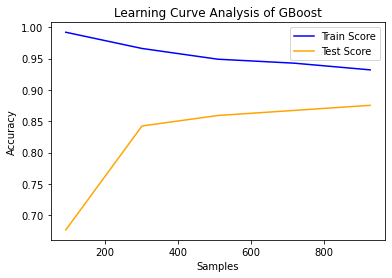

In [80]:
generic_lc("GBoost",GradientBoostingRegressor(),x,y)

(array([ 92, 301, 509, 718, 927]),
 array([0.9996963 , 0.99759542, 0.99307994, 0.99274548, 0.99232985]),
 array([0.45804793, 0.6700723 , 0.76533989, 0.78759609, 0.8308954 ]))

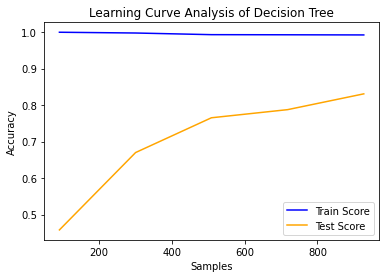

In [81]:
generic_lc("Decision Tree",DecisionTreeRegressor(),x,y)

(array([ 92, 301, 509, 718, 927]),
 array([0.8583702 , 0.84274332, 0.82584725, 0.80970948, 0.77959639]),
 array([0.59050102, 0.73741198, 0.74930664, 0.74607068, 0.73967535]))

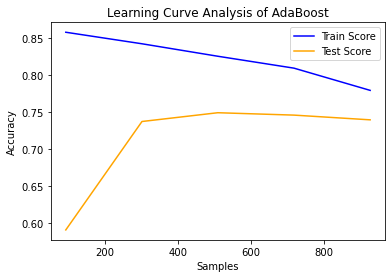

In [82]:
generic_lc("AdaBoost",AdaBoostRegressor(),x,y)